# 05 · Joint residual risk and diffusion clocks

**RQ2–RQ3:** Can explicit residual risk repair the smooth-factor model? Does
stochastic time scaling explain some calendar-gap behavior? This is a revised
development model, distinct from the frozen source-covariance benchmark.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from spde_covariance.empirical_research import load_research_evidence

evidence = load_research_evidence(Path("../experiments/results/shfe-research"))
print(evidence["protocol"]["status"])
print("Numerical source:", evidence["manifest"]["git_revision"])
print("Original baseline source:", evidence["protocol"]["baseline_source_revision"])
assert evidence["protocol"]["baseline_summary_sha256"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
LABELS = {
    "outright_3m": "Outright",
    "spread_3m_6m": "Spread",
    "butterfly_3m_6m_9m": "Butterfly",
    "factor": "Factor only",
    "joint": "Factor + residual",
    "source": "Source C (original)",
    "direct": "Direct",
    "unhedged": "Unhedged",
    "factor_adjusted": "Transport adjusted",
    "factor_unadjusted": "Unadjusted",
    "spde_local": "Local source C",
    "shrinkage": "Direct + shrinkage",
    "joint_calendar": "Joint / calendar",
    "joint_session": "Joint / session",
    "bootstrap_percentile_95": "95% block range",
    "bootstrap_standard_error": "Block SE",
    "realized_over_predicted_second_moment": "Realized / predicted",
    "predicted_rms_cny": "Forecast RMS (CNY)",
    "realized_rms_cny": "Realized RMS (CNY)",
    "mean_position_change_proxy": "Position-change proxy",
    "training_count_min_median_max": "Training count (min/median/max)",
    "minimum_relative_forecast_eigenvalue": "Min relative eigenvalue",
    "maximum_exact_transport_identity_absolute_error": "Max transport error",
    "all_forecast_psd_within_roundoff": "PSD within roundoff",
}


def readable_label(value):
    return LABELS.get(value, value.replace("_", " "))


def display_value(value):
    if value is None:
        return "Unavailable"
    if isinstance(value, float):
        return f"{value:.4g}"
    if isinstance(value, (list, tuple)):
        return "[" + ", ".join((display_value(v) for v in value)) + "]"
    if isinstance(value, dict):
        return "; ".join((f"{readable_label(k)}: {display_value(v)}" for k, v in value.items()))
    return readable_label(value) if isinstance(value, str) else str(value)


def table(rows, columns):
    cells = [[readable_label(c) for c in columns]] + [
        [display_value(r.get(c)) for c in columns] for r in rows
    ]
    widths = [max((len(row[i]) for row in cells)) for i in range(len(columns))]
    for row in cells:
        print(" | ".join((v.ljust(w) for v, w in zip(row, widths, strict=True))))

exploratory development on inspected 2024–2025 data
Numerical source: a2f99054886b3154a311665cee7cacd8e6af483c
Original baseline source: d284718c0e465d39886500ab2d85904183266747


## Model and estimand

For the current actual-contract set, collect historical adjacent changes and
their exact transport decomposition. For diffusion duration $h_i$, estimate

$$
z_i=\frac{1}{\sqrt{h_i}}\begin{pmatrix}r_i\\u_i\end{pmatrix},\qquad
\widehat Q=\frac1n\sum_i z_i z_i^\top,
\qquad \widehat K_{n+1}=h_{n+1}[E_{n+1},I]\widehat Q[E_{n+1},I]^\top.
$$

This retains factor/residual cross blocks and is PSD by construction. Optional
diagonal shrinkage changes the joint moment explicitly. The locally common
joint moment is an approximation across contract ages, not physical forcing
identification. Compare with factor-only and raw direct second moments on the
**same complete historical intervals**.

Physical transport always uses ACT/365.25 maturity time. Only the diffusion
normalizer changes: $h_i=\Delta_i$ or one session/252. The original source-$C$
pipeline remains a separate calendar-time control.

In [2]:
joint = evidence["joint"]
print(joint["clock_convention"])
print(joint["selection_criterion"])
selected = []
for method, selection in joint["selection"].items():
    selected.append(
        {
            "method": method,
            **selection["selected"],
            "validation origins": selection["common_validation_origins"],
            "last outcome": selection["selection_last_outcome"],
        }
    )
    assert selection["selection_last_outcome"] <= joint["chronology"]["validation_end"]
table(selected, ["method", "window", "clock", "shrinkage", "validation origins", "last outcome"])

physical ACT/365.25 maturity transport unchanged; diffusion normalization calendar ACT/365.25 or one session/252
mean validation QLIKE across outright, spread and butterfly on identical validation origins within each rule; exact ties longer window then calendar clock then smaller shrinkage
method              | window | clock    | Direct + shrinkage | validation origins | last outcome
Factor only         | 63     | calendar | 0                  | 231                | 2023-12-29  
Factor + residual   | 63     | calendar | 0                  | 231                | 2023-12-29  
Direct              | 63     | calendar | 0                  | 231                | 2023-12-29  
Source C (original) | 252    | calendar | 0                  | 231                | 2023-12-29  


In [3]:
primary_methods = ["factor", "joint", "direct"]
table(
    [r for r in joint["risk_summary"] if r["method"] in primary_methods],
    ["exposure", "method", "common_count", "qlike", "realized_over_predicted_second_moment"],
)
table(
    [
        r
        for r in joint["paired_scores"]
        if r["score"] == "qlike" and r["method"] in primary_methods and (r["reference"] == "direct")
    ],
    ["exposure", "method", "reference", "count", "mean", "bootstrap_percentile_95"],
)

exposure  | method            | common count | qlike | Realized / predicted
Outright  | Direct            | 484          | 17.28 | 1.09                
Outright  | Factor only       | 484          | 17.27 | 1.103               
Outright  | Factor + residual | 484          | 17.28 | 1.076               
Spread    | Direct            | 484          | 13.64 | 0.4563              
Spread    | Factor only       | 484          | 15.17 | 2.218               
Spread    | Factor + residual | 484          | 13.71 | 0.4068              
Butterfly | Direct            | 484          | 15.07 | 0.6582              
Butterfly | Factor only       | 484          | 23.76 | 7.563               
Butterfly | Factor + residual | 484          | 15.07 | 0.6254              
exposure  | method            | reference | count | mean      | 95% block range      
Outright  | Factor only       | Direct    | 484   | -0.004653 | [-0.02678, 0.01268]  
Outright  | Factor + residual | Direct    | 484   | 0.0002244 | [-0.

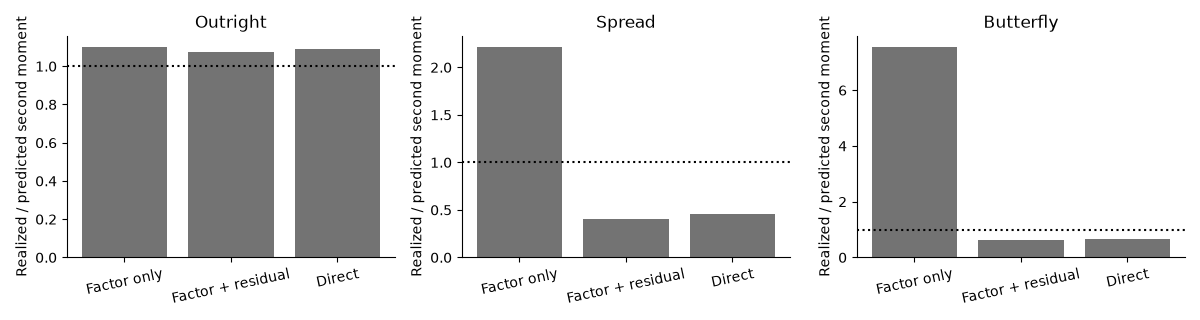

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, exposure in zip(axes, ["outright_3m", "spread_3m_6m", "butterfly_3m_6m_9m"], strict=True):
    rows = [
        next(
            (
                r
                for r in joint["risk_summary"]
                if r["exposure"] == exposure and r["method"] == method
            )
        )
        for method in primary_methods
    ]
    ax.bar(
        range(len(rows)), [r["realized_over_predicted_second_moment"] for r in rows], color="0.45"
    )
    ax.axhline(1, color="black", linestyle=":")
    ax.set_xticks(range(len(rows)), [readable_label(r["method"]) for r in rows], rotation=12)
    ax.set(title=readable_label(exposure), ylabel="Realized / predicted second moment")
fig.tight_layout()
plt.show()

## Cross-covariances and numerical checks

Dropping cross terms would impose independence without evidence. The components
below sum to a joint-model forecast; factor/direct controls can use a different
kernel. Numerical PSD/rank diagnostics establish matrix feasibility, not a
statistical or market-model guarantee. The table of selected policies above
uses identical historical support. Fixed calendar/session companions below
are sensitivity controls, not additional selected winners. The selected joint
policy coincides with its calendar companion; duplicate bars are omitted.

Complete per-policy components, clock-gap strata and numerical diagnostics are
preserved in [the joint aggregate file](../experiments/results/shfe-research/joint.json).
The compact audit retains all 11 policies, including availability and PSD checks.

In [5]:
components = []
for r in joint["risk_components"]:
    if r["method"] == "joint":
        total = r["mean_factor_plus_residual_second_moment_cny2"]
        components.append(
            {
                "exposure": r["exposure"],
                "count": r["count"],
                **{f"{k} share": v / total for k, v in r["components_cny2"].items()},
            }
        )
table(components, ["exposure", "count", "factor share", "residual share", "cross share"])
print("Fixed-clock sensitivity (all scored origins):")
table(
    [r for r in joint["risk_summary"] if r["method"] in ("joint_calendar", "joint_session")],
    ["method", "exposure", "common_count", "qlike", "realized_over_predicted_second_moment"],
)
audit = []
for method, diagnostic in joint["numerical_diagnostics"].items():
    counts = joint["availability"][method]
    audit.append(
        {
            "method": method,
            "issued / attempted": f"{counts['issued']} / {counts['attempted']}",
            "fully scored": counts["fully_scored"],
            "training_count_min_median_max": diagnostic.get("training_count_min_median_max"),
            "all_forecast_psd_within_roundoff": diagnostic.get("all_forecast_psd_within_roundoff"),
            "minimum_relative_forecast_eigenvalue": diagnostic.get(
                "minimum_relative_forecast_eigenvalue"
            ),
        }
    )
    if diagnostic["available"]:
        assert diagnostic["all_forecast_psd_within_roundoff"]
table(
    audit,
    [
        "method",
        "issued / attempted",
        "fully scored",
        "training_count_min_median_max",
        "all_forecast_psd_within_roundoff",
        "minimum_relative_forecast_eigenvalue",
    ],
)
print(
    "Maximum absolute transport identity error:",
    max(
        (
            r.get("maximum_exact_transport_identity_absolute_error", 0.0)
            for r in joint["numerical_diagnostics"].values()
        )
    ),
)

exposure  | count | factor share | residual share | cross share
Outright  | 484   | 0.9761       | 0.01075        | 0.01311    
Spread    | 484   | 0.1834       | 0.6542         | 0.1624     
Butterfly | 484   | 0.08268      | 0.8136         | 0.1037     
Fixed-clock sensitivity (all scored origins):
method           | exposure  | common count | qlike | Realized / predicted
Joint / calendar | Outright  | 484          | 17.28 | 1.076               
Joint / session  | Outright  | 484          | 17.45 | 1.16                
Joint / calendar | Spread    | 484          | 13.71 | 0.4068              
Joint / session  | Spread    | 484          | 13.63 | 0.5103              
Joint / calendar | Butterfly | 484          | 15.07 | 0.6254              
Joint / session  | Butterfly | 484          | 14.97 | 0.7823              
method              | issued / attempted | fully scored | Training count (min/median/max) | PSD within roundoff | Min relative eigenvalue
Factor only         | 484 / 484    

## Interpretation and next decision

Validation selects 63 intervals, calendar diffusion and zero shrinkage for the
joint model. Joint spread/butterfly QLIKE is 13.710/15.069, versus factor-only
15.172/23.760 and direct 13.637/15.066. Residual risk repairs the weak factor
model but does not establish superiority over direct covariance. Session scaling
improves curvature scores while worsening outright scores in this development
sample; the selected calendar policy remains unchanged.

Compare the selected practical policies and the fixed-clock companions separately.
Residual risk and a different clock can improve a weak factor forecast without
establishing an SPDE advantage over raw direct risk. Use the matched attribution
results and effective sample counts to qualify the conclusion. Test the selected
revised policy on an uninspected period before promoting it beyond development.

## Reproduction and research boundary

This notebook reads checksummed aggregate evidence, not raw exchange files.
The numerical algorithms are in `spde_covariance`; use the
[protocol](../docs/empirical-research-protocol.md) to rerun local calibration.
Execute this notebook with `uv run python scripts/check_notebook.py notebooks/05_joint_residual_risk_and_clocks.ipynb`.

The original historical benchmark remains fixed. New analyses on the inspected
2024–2025 period are exploratory, even though forecast issuance is past-only.
No final untouched confirmation period, executable trading backtest or physical
forcing identification is claimed. See the [roadmap](../README.md).

The displayed tables emphasize the primary comparisons. Complete sensitivity,
availability and numerical diagnostics remain in the checksummed aggregate files:
[data](../experiments/results/shfe-research/data.json),
[representation](../experiments/results/shfe-research/representation.json),
[attribution](../experiments/results/shfe-research/attribution.json),
[scores](../experiments/results/shfe-research/scores.json), and
[joint risk / hedging](../experiments/results/shfe-research/joint.json).